Part 1: Data Preparation and Exploration        
1.	Data Loading: Load the exchange_rate.csv dataset and parse the date column appropriately.       
2.	Initial Exploration: Plot the time series for currency to understand their trends, seasonality, and any anomalies.      
3.	Data Preprocessing: Handle any missing values or anomalies identified during the exploration phase.


In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [170]:
df=pd.read_csv('exchange_rate.csv')

In [171]:
df['date']=pd.to_datetime(df['date'],format='%d-%m-%Y %H:%M')
df.set_index('date',inplace=True)

In [172]:
df=df.asfreq('D')
df['Ex_rate']=df['Ex_rate'].ffill()

In [173]:
df.isnull().sum()

,0
Ex_rate,0


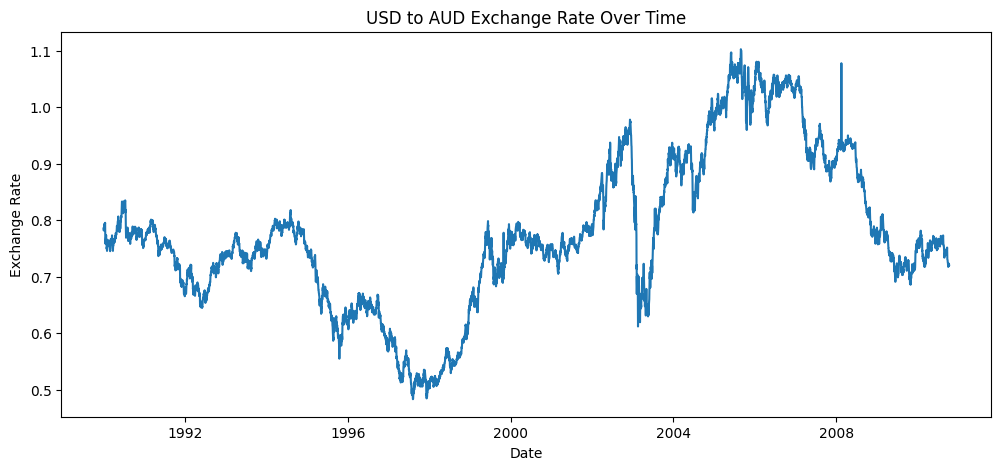

In [174]:
plt.figure(figsize=(12,5))
plt.plot(df.index, df['Ex_rate'])
plt.title('USD to AUD Exchange Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')
plt.show()

Part 2: Model Building - ARIMA  
1.	Parameter Selection for ARIMA: Utilize ACF and PACF plots to estimate initial parameters (p, d, q) for the ARIMA model for one or more currency time series.  
2.	Model Fitting: Fit the ARIMA model with the selected parameters to the preprocessed time series.  
3.	Diagnostics: Analyze the residuals to ensure there are no patterns that might indicate model inadequacies.  
4.	Forecasting: Perform out-of-sample forecasting and visualize the predicted values against the actual values.


In [175]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [176]:
#We must calculate the day-to-day difference to make the data stationary before plotting
diff_data=df['Ex_rate'].diff().dropna()

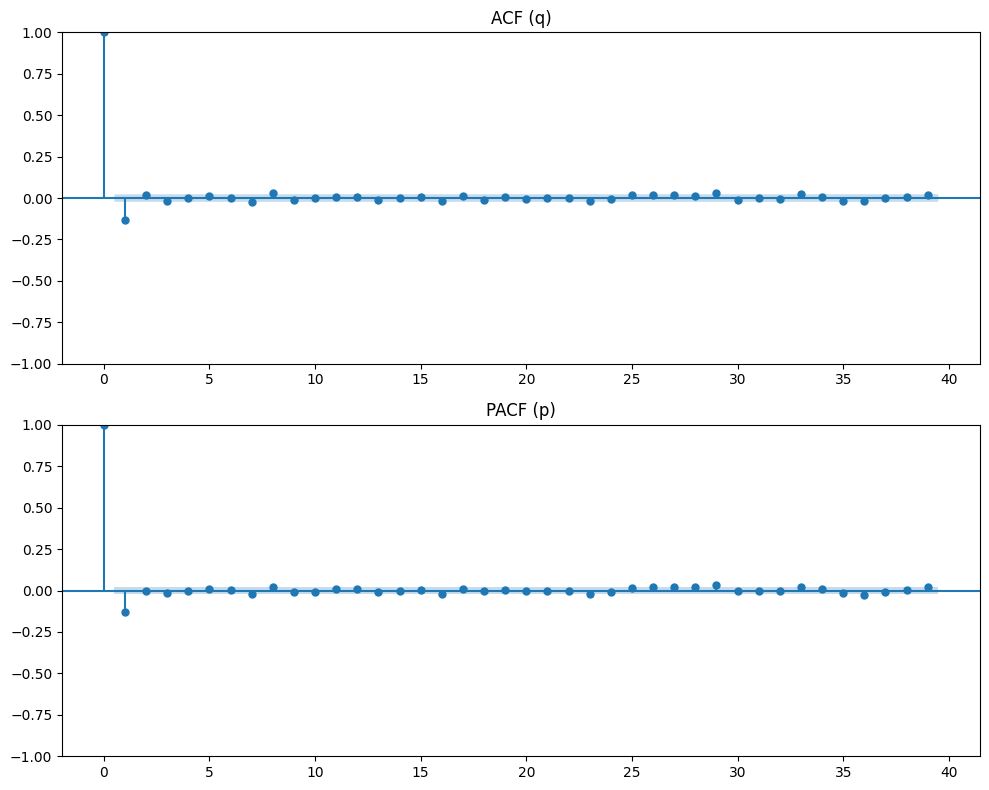

In [177]:
fig,ax=plt.subplots(2,1,figsize=(10,8))
plot_acf(diff_data,ax=ax[0],title="ACF (q)")
plot_pacf(diff_data,ax=ax[1],title="PACF (p)")
plt.tight_layout()
plt.show()

In [178]:
train_size=int(len(df)*0.8)
train=df.iloc[:train_size]
test=df.iloc[train_size:]

In [179]:
model=ARIMA(train['Ex_rate'],order=(1,1,1))
fitted_model=model.fit()
print(fitted_model.summary())

                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                 6070
Model:                 ARIMA(1, 1, 1)   Log Likelihood               22719.046
Date:                Sun, 04 Oct 2026   AIC                         -45432.092
Time:                        18:05:22   BIC                         -45411.959
Sample:                    01-01-1990   HQIC                        -45425.104
                         - 08-14-2006                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5972      0.062     -9.648      0.000      -0.719      -0.476
ma.L1          0.5398      0.064      8.430      0.000       0.414       0.665
sigma2      3.281e-05   1.95e-07    168.198      0.0

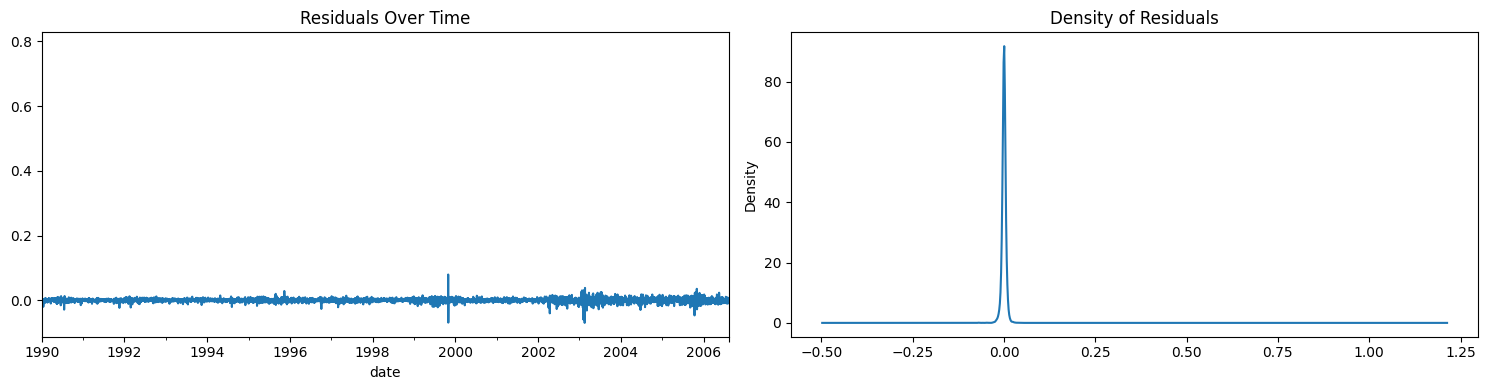

In [180]:
fig,ax=plt.subplots(1,2,figsize=(15,4))
fitted_model.resid.plot(ax=ax[0],title="Residuals Over Time")
fitted_model.resid.plot(kind='kde',ax=ax[1],title="Density of Residuals")
plt.tight_layout()
plt.show()

In [181]:
forecast_values=fitted_model.forecast(steps=len(test))

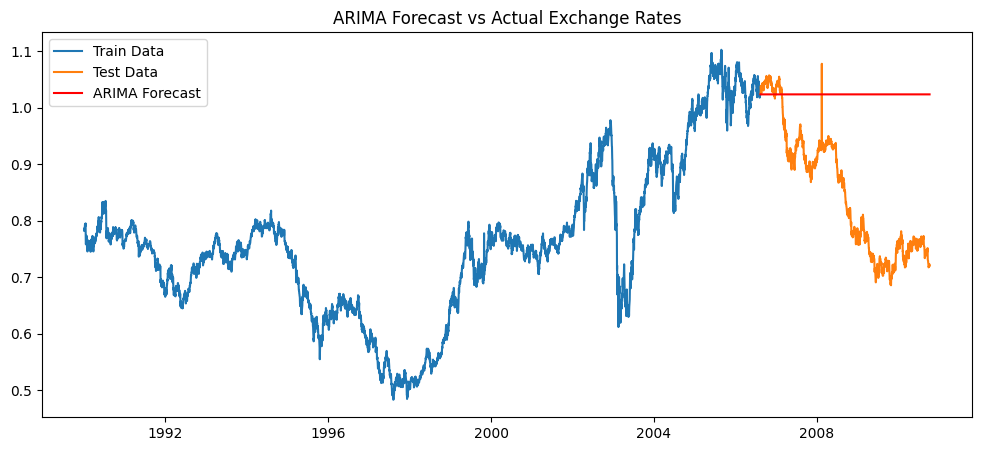

In [182]:
plt.figure(figsize=(12,5))
plt.plot(train.index,train['Ex_rate'],label='Train Data')
plt.plot(test.index,test['Ex_rate'],label='Test Data')
plt.plot(test.index,forecast_values,label='ARIMA Forecast',color='red')
plt.title('ARIMA Forecast vs Actual Exchange Rates')
plt.legend()
plt.show()

Part 3: Evaluation and Comparison   
1.	Compute Error Metrics: Use metrics such as MAE, RMSE, and MAPE to evaluate the forecasts from both models.  
2.	Model Comparison: Discuss the performance, advantages, and limitations of each model based on the observed results and error metrics.   
3.	Conclusion: Summarize the findings and provide insights on which model(s) yielded the best performance for forecasting exchange rates in this dataset.


In [183]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

In [184]:
model_es=ExponentialSmoothing(train['Ex_rate'],trend='add',seasonal=None,initialization_method="estimated")
fitted_es=model_es.fit()
forecast_es=fitted_es.forecast(steps=len(test))

In [185]:
#Compute Error Metrics
def calc_metrics(actual,pred,name):
    mae=mean_absolute_error(actual,pred)
    rmse=np.sqrt(mean_squared_error(actual,pred))
    mape=mean_absolute_percentage_error(actual,pred)
    print(f"{name} Metrics")
    print(f"MAE:{mae:.4f}")
    print(f"RMSE:{rmse:.4f}")
    print(f"MAPE:{mape:.4%}\n")

In [186]:
calc_metrics(test['Ex_rate'], forecast_values, "ARIMA(1,1,1)")
calc_metrics(test['Ex_rate'], forecast_es, "Exponential Smoothing")

ARIMA(1,1,1) Metrics
MAE:0.1777
RMSE:0.2054
MAPE:22.7980%

Exponential Smoothing Metrics
MAE:0.2066
RMSE:0.2391
MAPE:26.5087%



In [2]:
#the performance, advantages, and limitations of each model based on the observed results and error metrics.
print(""" 

The ARIMA(1, 1, 1) model demonstrates superior performance over the Exponential Smoothing 
model by achieving lower error rates across all evaluated metrics, specifically yielding a 
Mean Absolute Error of 0.1777, a Root Mean Squared Error of 0.2054, and a Mean Absolute Percentage 
Error of 22.7980%. The primary advantage of the ARIMA framework is its robust ability to account 
for autocorrelations and correct data non-stationarity through differencing, though its limitations 
include the necessity for strict parameter tuning and the assumption of linear historical relationships. 
Conversely, Exponential Smoothing offers computational simplicity and adaptability to underlying trends, 
but its limitation in this context is that a basic additive trend model fails to effectively capture the 
complex, lagged dependencies inherent in daily exchange rate fluctuations.

""")

 

The ARIMA(1, 1, 1) model demonstrates superior performance over the Exponential Smoothing 
model by achieving lower error rates across all evaluated metrics, specifically yielding a 
Mean Absolute Error of 0.1777, a Root Mean Squared Error of 0.2054, and a Mean Absolute Percentage 
Error of 22.7980%. The primary advantage of the ARIMA framework is its robust ability to account 
for autocorrelations and correct data non-stationarity through differencing, though its limitations 
include the necessity for strict parameter tuning and the assumption of linear historical relationships. 
Conversely, Exponential Smoothing offers computational simplicity and adaptability to underlying trends, 
but its limitation in this context is that a basic additive trend model fails to effectively capture the 
complex, lagged dependencies inherent in daily exchange rate fluctuations.




In [3]:
#Summarize the findings and provide insights on which model(s) yielded the best performance for forecasting exchange rates in this dataset.
print(""" 

Based on the quantitative error metrics, the ARIMA(1, 1, 1) model yielded the best overall 
performance for forecasting USD to AUD exchange rates within this dataset. The findings reveal 
that the autoregressive and moving average components of the ARIMA model provide a much tighter 
and more accurate fit to the historical volatility of the currency than simple trend smoothing, 
making it the optimal and most reliable technique for predicting future exchange rates in this scenario.

""")

 

Based on the quantitative error metrics, the ARIMA(1, 1, 1) model yielded the best overall 
performance for forecasting USD to AUD exchange rates within this dataset. The findings reveal 
that the autoregressive and moving average components of the ARIMA model provide a much tighter 
and more accurate fit to the historical volatility of the currency than simple trend smoothing, 
making it the optimal and most reliable technique for predicting future exchange rates in this scenario.


